# Faisalabad LST aur Rainfall Analysis

Yeh notebook local `LST_Data` (MODIS MOD11A1 HDF4) aur `Rainfall_Data` (IMERG monthly HDF5) folders ko inspect, clean, scale aur analyse karti hai. Faisalabad ke liye representative ROI 31.2–31.6°N, 72.9–73.3°E hai.

**Data-period caveat:** LST files 2024 ke DOY 117–366 (sirf ek partial year) ke hain; rainfall Jan 2001–Apr 2009 tak hai. Periods overlap nahi karte, isliye cross-variable correlation ya direct same-period comparison nahi kiya jayega. Rainfall trend sirf complete calendar years par estimate hoga; 2009 partial hai. Ek partial LST year se long-term climate trend nahi nikala ja sakta.

Notebook CSV tables aur PNG graphs `outputs/` me bhi save karegi.

## 1. Libraries aur TensorFlow runtime
HDF4/HDF5 readers, NumPy, matplotlib aur scipy installed hain. TensorFlow cleaning use hogi agar selected kernel me TensorFlow native runtime load ho; warna clearly reported NumPy fallback chalega.

In [1]:
from pathlib import Path
import re
import csv
import calendar
from datetime import datetime, timedelta
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from pyhdf.SD import SD, SDC

try:
    import tensorflow as tf
    TF_AVAILABLE = True
    print(f'TensorFlow {tf.__version__} runtime loaded.')
except ImportError as exc:
    TF_AVAILABLE = False
    TF_IMPORT_ERROR = f'{type(exc).__name__}: {exc}'
    print('TensorFlow package is installed, but its native runtime could not load.')
    print('Cleaning will use the explicitly reported NumPy fallback. Details:', TF_IMPORT_ERROR[:500])

plt.style.use('seaborn-v0_8-whitegrid')

def print_table(rows, limit=None):
    rows = rows if limit is None else rows[:limit]
    if not rows:
        print('(no rows)')
        return
    columns = list(rows[0])
    print(' | '.join(columns))
    for row in rows:
        print(' | '.join(str(row.get(column, '')) for column in columns))

def save_csv(path, rows):
    if not rows:
        return
    columns = list(rows[0])
    with path.open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=columns)
        writer.writeheader()
        for row in rows:
            writer.writerow({key: value.isoformat() if hasattr(value, 'isoformat') else value for key, value in row.items()})


[TensorFlow DLL Diagnostic] Analyzing: c:\Users\Mr.Laptop Point\AppData\Local\Programs\Python\Python314\Lib\site-packages\tensorflow\python\_pywrap_tensorflow_internal.pyd
[Error] Failed to load _pywrap_tensorflow_common.dll: INITIALIZATION FAILED (0x45A) - The DLL's DllMain returned false.
    Hint: This often happens if your CPU lacks required instructions (like AVX/AVX2)
    or if the Microsoft Visual C++ Redistributable is outdated/missing.
TensorFlow package is installed, but its native runtime could not load.
Cleaning will use the explicitly reported NumPy fallback. Details: ImportError: Traceback (most recent call last):
  File "c:\Users\Mr.Laptop Point\AppData\Local\Programs\Python\Python314\Lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 74, in <module>
    from tensorflow.python._pywrap_tensorflow_internal import *
ImportError: DLL load failed while importing _pywrap_tensorflow_internal: A dynamic link library (DLL) initialization routine failed.


Failed to 

## 2. Paths, ROI aur raw data inspection
MODIS sinusoidal tile metadata se Faisalabad ROI ka pixel window niklega. IMERG me coordinate arrays se isi geographic box ka subset liya jayega.

In [2]:
ROOT = Path.cwd()
LST_DIR = ROOT / 'LST_Data'
RAIN_DIR = ROOT / 'Rainfall_Data'
OUT_DIR = ROOT / 'outputs'
OUT_DIR.mkdir(exist_ok=True)

LAT_BOUNDS = (31.2, 31.6)
LON_BOUNDS = (72.9, 73.3)
lst_files = sorted(LST_DIR.glob('*.hdf'))
rain_files = sorted(RAIN_DIR.glob('*.HDF5'))
if not lst_files:
    raise FileNotFoundError(f'No MODIS .hdf files found in {LST_DIR}')
if not rain_files:
    raise FileNotFoundError(f'No IMERG .HDF5 files found in {RAIN_DIR}')

def lst_date_from_name(path):
    match = re.search(r'\.A(\d{4})(\d{3})\.', path.name)
    if not match:
        raise ValueError(f'Cannot parse MODIS year/day-of-year from {path.name}')
    year, doy = map(int, match.groups())
    return datetime(year, 1, 1).date() + timedelta(days=doy - 1)

def rain_date_from_name(path):
    match = re.search(r'IMERG\.(\d{8})-', path.name)
    if not match:
        raise ValueError(f'Cannot parse IMERG date from {path.name}')
    return datetime.strptime(match.group(1), '%Y%m%d').date()

lst_dates = [lst_date_from_name(p) for p in lst_files]
rain_dates = [rain_date_from_name(p) for p in rain_files]
inspection = [
    {'Dataset': 'MODIS daily LST', 'Files': len(lst_files), 'Start': min(lst_dates), 'End': max(lst_dates), 'Format': 'HDF4 / MOD11A1'},
    {'Dataset': 'IMERG monthly rainfall', 'Files': len(rain_files), 'Start': min(rain_dates), 'End': max(rain_dates), 'Format': 'HDF5 / 3B-MO'}
]
print_table(inspection)
print('ROI:', LAT_BOUNDS, 'latitude,', LON_BOUNDS, 'longitude')
print('LST sample file:', lst_files[0].name)
print('Rain sample file:', rain_files[0].name)
with h5py.File(rain_files[0], 'r') as sample:
    print('IMERG precipitation dataset:', sample['Grid/precipitation'].shape,
          sample['Grid/precipitation'].attrs.get('units', 'unit not listed'))

Dataset | Files | Start | End | Format
MODIS daily LST | 249 | 2024-04-26 | 2024-12-31 | HDF4 / MOD11A1
IMERG monthly rainfall | 100 | 2001-01-01 | 2009-04-01 | HDF5 / 3B-MO
ROI: (31.2, 31.6) latitude, (72.9, 73.3) longitude
LST sample file: MOD11A1.A2024117.h24v05.061.2024118093646.hdf
Rain sample file: 3B-MO.MS.MRG.3IMERG.20010101-S000000-E235959.01.V07B.HDF5
IMERG precipitation dataset: (1, 3600, 1800) b'mm/hr'


## 3. LST scale factor, quality filter aur daily dataset
MOD11A1 `LST_Day_1km` ka scale factor 0.02 K hai. QC ke pehle do bits `00` hone par hi good-quality retrieval rakha jayega; fill/invalid raw values discard honge. Temperature ko °C me convert kiya jayega.

In [3]:
def metadata_point(struct_text, key):
    match = re.search(rf'{key}=\(([-+0-9.eE]+),([-+0-9.eE]+)\)', struct_text)
    if not match:
        raise ValueError(f'MODIS metadata does not contain {key}')
    return tuple(map(float, match.groups()))

def modis_roi_window(struct_text):
    radius = 6371007.181
    upper_left_x, upper_left_y = metadata_point(struct_text, 'UpperLeftPointMtrs')
    lower_right_x, lower_right_y = metadata_point(struct_text, 'LowerRightMtrs')
    resolution = (lower_right_x - upper_left_x) / 1200.0
    projected = []
    for latitude in LAT_BOUNDS:
        for longitude in LON_BOUNDS:
            lat_rad = np.deg2rad(latitude)
            lon_rad = np.deg2rad(longitude)
            projected.append((radius * lon_rad * np.cos(lat_rad), radius * lat_rad))
    x_values, y_values = zip(*projected)
    row0 = max(0, int(np.floor((upper_left_y - max(y_values)) / resolution)))
    row1 = min(1200, int(np.ceil((upper_left_y - min(y_values)) / resolution)))
    col0 = max(0, int(np.floor((min(x_values) - upper_left_x) / resolution)))
    col1 = min(1200, int(np.ceil((max(x_values) - upper_left_x) / resolution)))
    if row0 >= row1 or col0 >= col1:
        raise ValueError('Faisalabad ROI does not intersect the MODIS tile in the supplied files.')
    return slice(row0, row1), slice(col0, col1)

def clean_temperature_values(values):
    values = np.asarray(values, dtype=np.float32)
    valid_range = np.isfinite(values) & (values >= -80.0) & (values <= 80.0)
    if TF_AVAILABLE:
        tensor = tf.convert_to_tensor(values, dtype=tf.float32)
        cleaned = tf.boolean_mask(tensor, tf.convert_to_tensor(valid_range))
        return cleaned.numpy()
    return values[valid_range]

def read_lst_roi(path):
    hdf = SD(str(path), SDC.READ)
    try:
        struct_text = hdf.attributes()['StructMetadata.0']
        row_slice, col_slice = modis_roi_window(struct_text)
        start = [row_slice.start, col_slice.start]
        count = [row_slice.stop - row_slice.start, col_slice.stop - col_slice.start]
        raw = np.asarray(hdf.select('LST_Day_1km').get(start=start, count=count))
        qc = np.asarray(hdf.select('QC_Day').get(start=start, count=count))
        good_qc = (qc & 0b11) == 0
        valid_raw = good_qc & (raw >= 7500) & (raw <= 65535) & (raw != 0)
        celsius = raw[valid_raw].astype(np.float32) * 0.02 - 273.15
        return clean_temperature_values(celsius), int(valid_raw.sum()), int(raw.size)
    finally:
        hdf.end()

lst_rows = []
for path in lst_files:
    date = lst_date_from_name(path)
    values, qc_valid_pixels, roi_pixels = read_lst_roi(path)
    lst_rows.append({
        'Date': date,
        'LST_Celsius': float(values.mean()) if values.size else np.nan,
        'LST_Median_Celsius': float(np.median(values)) if values.size else np.nan,
        'Valid_Pixels': int(values.size),
        'QC_Passing_Pixels': qc_valid_pixels,
        'ROI_Pixels': roi_pixels,
    })
lst_daily = sorted(lst_rows, key=lambda row: row['Date'])
lst_monthly = []
for month in sorted({row['Date'].replace(day=1) for row in lst_daily}):
    observations = [row for row in lst_daily if row['Date'].replace(day=1) == month]
    valid_rows = [row for row in observations if np.isfinite(row['LST_Celsius'])]
    lst_monthly.append({
        'Month': month,
        'LST_Celsius': float(np.mean([row['LST_Celsius'] for row in valid_rows])) if valid_rows else np.nan,
        'Valid_Days': len(valid_rows),
        'Mean_Valid_Pixels': float(np.mean([row['Valid_Pixels'] for row in valid_rows])) if valid_rows else 0.0,
        'QC_Passing_Pixels': sum(row['QC_Passing_Pixels'] for row in observations),
    })
lst_annual = []
for year in sorted({row['Date'].year for row in lst_daily}):
    observations = [row for row in lst_daily if row['Date'].year == year]
    valid_rows = [row for row in observations if np.isfinite(row['LST_Celsius'])]
    months_with_data = len({row['Date'].month for row in observations})
    lst_annual.append({
        'Year': year,
        'LST_Celsius': float(np.mean([row['LST_Celsius'] for row in valid_rows])) if valid_rows else np.nan,
        'Months_With_Data': months_with_data,
        'Valid_Days': len(valid_rows),
        'Complete_Year': months_with_data == 12,
    })

print('Loaded', len(lst_daily), 'daily files; ROI window is', lst_daily[0]['ROI_Pixels'], 'pixels per file.')
print('TensorFlow cleaning active:', TF_AVAILABLE)
print('First daily records:')
print_table(lst_daily, limit=5)
print('Monthly LST dataset:')
print_table(lst_monthly)

Loaded 249 daily files; ROI window is 3626 pixels per file.
TensorFlow cleaning active: False
First daily records:
Date | LST_Celsius | LST_Median_Celsius | Valid_Pixels | QC_Passing_Pixels | ROI_Pixels
2024-04-26 | 30.615310668945312 | 30.8699951171875 | 64 | 64 | 3626
2024-04-27 | 32.01536560058594 | 31.970001220703125 | 3361 | 3361 | 3626
2024-04-28 | 31.902381896972656 | 32.92999267578125 | 176 | 176 | 3626
2024-04-29 | 32.16691970825195 | 32.149993896484375 | 3297 | 3297 | 3626
2024-04-30 | nan | nan | 0 | 0 | 3626
Monthly LST dataset:
Month | LST_Celsius | Valid_Days | Mean_Valid_Pixels | QC_Passing_Pixels
2024-04-01 | 31.674994468688965 | 4 | 1724.5 | 6898
2024-05-01 | 40.5830438548121 | 29 | 2982.7586206896553 | 86500
2024-06-01 | 38.31858299255371 | 25 | 1841.56 | 46039
2024-07-01 | 32.90243251507099 | 13 | 1966.6153846153845 | 25566
2024-08-01 | 32.45144626072475 | 7 | 1218.5714285714287 | 8530
2024-09-01 | 32.040676991144814 | 24 | 2420.3333333333335 | 58088
2024-10-01 | 30.

## 4. Rainfall scale/unit handling aur monthly/annual datasets
IMERG monthly `precipitation` ka unit mm/hr hai. Spatial ROI ke valid non-negative rates ka mean lekar month ke hours se multiply karke estimated monthly depth (mm) banegi. 2009 ko partial year mark kiya jayega.

In [4]:
with h5py.File(rain_files[0], 'r') as sample:
    rain_lats = sample['Grid/lat'][:]
    rain_lons = sample['Grid/lon'][:]
lat_indices = np.flatnonzero((rain_lats >= LAT_BOUNDS[0]) & (rain_lats <= LAT_BOUNDS[1]))
lon_indices = np.flatnonzero((rain_lons >= LON_BOUNDS[0]) & (rain_lons <= LON_BOUNDS[1]))
if not len(lat_indices) or not len(lon_indices):
    raise ValueError('IMERG grid has no cells inside the configured Faisalabad ROI.')
lat_slice = slice(int(lat_indices.min()), int(lat_indices.max()) + 1)
lon_slice = slice(int(lon_indices.min()), int(lon_indices.max()) + 1)

rain_rows = []
for path in rain_files:
    date = rain_date_from_name(path)
    with h5py.File(path, 'r') as h5:
        rates = np.asarray(h5['Grid/precipitation'][0, lon_slice, lat_slice], dtype=np.float32)
        fill_value = h5['Grid/precipitation'].attrs.get('_FillValue', -9999.9)
    valid = np.isfinite(rates) & (rates >= 0) & (rates != fill_value)
    good_rates = rates[valid]
    mean_rate = float(good_rates.mean()) if good_rates.size else np.nan
    hours_in_month = calendar.monthrange(date.year, date.month)[1] * 24
    rain_rows.append({'Date': date, 'Mean_Rate_mm_per_hour': mean_rate,
                      'Rain_mm_per_month': mean_rate * hours_in_month if np.isfinite(mean_rate) else np.nan,
                      'Valid_Grid_Cells': int(good_rates.size), 'ROI_Grid_Cells': int(rates.size),
                      'Year': date.year, 'Month_Number': date.month})

rain_monthly = sorted(rain_rows, key=lambda row: row['Date'])
rain_annual = []
for year in sorted({row['Year'] for row in rain_monthly}):
    observations = [row for row in rain_monthly if row['Year'] == year]
    valid_months = [row for row in observations if np.isfinite(row['Rain_mm_per_month'])]
    months_with_data = len({row['Month_Number'] for row in observations})
    rain_annual.append({
        'Year': year,
        'Rain_mm_per_year': float(sum(row['Rain_mm_per_month'] for row in valid_months)),
        'Months_With_Data': months_with_data,
        'Valid_Months': len(valid_months),
        'Complete_Year': months_with_data == 12 and len(valid_months) == 12,
    })
print(f'IMERG ROI: {len(lon_indices)} longitude x {len(lat_indices)} latitude cells.')
print('First monthly rainfall records:')
print_table(rain_monthly, limit=5)
print('Annual rainfall dataset:')
print_table(rain_annual)

IMERG ROI: 4 longitude x 4 latitude cells.
First monthly rainfall records:
Date | Mean_Rate_mm_per_hour | Rain_mm_per_month | Valid_Grid_Cells | ROI_Grid_Cells | Year | Month_Number
2001-01-01 | 0.004999999888241291 | 3.7199999168515205 | 16 | 16 | 2001 | 1
2001-02-01 | 0.005562500096857548 | 3.738000065088272 | 16 | 16 | 2001 | 2
2001-03-01 | 0.008937500417232513 | 6.64950031042099 | 16 | 16 | 2001 | 3
2001-04-01 | 0.05437500402331352 | 39.150002896785736 | 16 | 16 | 2001 | 4
2001-05-01 | 0.02225000038743019 | 16.554000288248062 | 16 | 16 | 2001 | 5
Annual rainfall dataset:
Year | Rain_mm_per_year | Months_With_Data | Valid_Months | Complete_Year
2001 | 373.74300895258784 | 12 | 12 | True
2002 | 311.7870151922107 | 12 | 12 | True
2003 | 440.26952493935823 | 12 | 12 | True
2004 | 398.2920151896542 | 12 | 12 | True
2005 | 499.0740186693147 | 12 | 12 | True
2006 | 484.59151574224234 | 12 | 12 | True
2007 | 461.6250273697078 | 12 | 12 | True
2008 | 600.346530337818 | 12 | 12 | True
2009 |

## 5. Trend analysis
Annual rainfall totals ke linear trend me sirf 12/12-month years honge. LST annual dataset output hota hai, lekin 2024 partial hone ke kaaran uska multi-year trend report nahi kiya jayega.

In [5]:
rain_complete_years = [row for row in rain_annual if row['Complete_Year'] and np.isfinite(row['Rain_mm_per_year'])]
if len(rain_complete_years) < 3:
    raise ValueError('At least 3 complete annual rainfall totals are required for trend regression.')
rain_trend = linregress([row['Year'] for row in rain_complete_years],
                        [row['Rain_mm_per_year'] for row in rain_complete_years])
rain_trend_summary = {
    'Complete years used': f"{rain_complete_years[0]['Year']}–{rain_complete_years[-1]['Year']}",
    'n years': len(rain_complete_years),
    'Slope (mm/year)': float(rain_trend.slope),
    'R-squared': float(rain_trend.rvalue ** 2),
    'p-value': float(rain_trend.pvalue),
}
print('Annual rainfall trend:', rain_trend_summary)
print('Annual LST dataset:')
print_table(lst_annual)

Annual rainfall trend: {'Complete years used': '2001–2008', 'n years': 8, 'Slope (mm/year)': 30.585270077052492, 'R-squared': 0.7287144137532853, 'p-value': 0.007001775128026462}
Annual LST dataset:
Year | LST_Celsius | Months_With_Data | Valid_Days | Complete_Year
2024 | 32.37043181061745 | 9 | 160 | False


## 6. Graphs
Har figure notebook me render hogi aur PNG ke roop me `outputs/` me save hogi. Missing/low-quality observations ko zero nahi maana gaya hai.

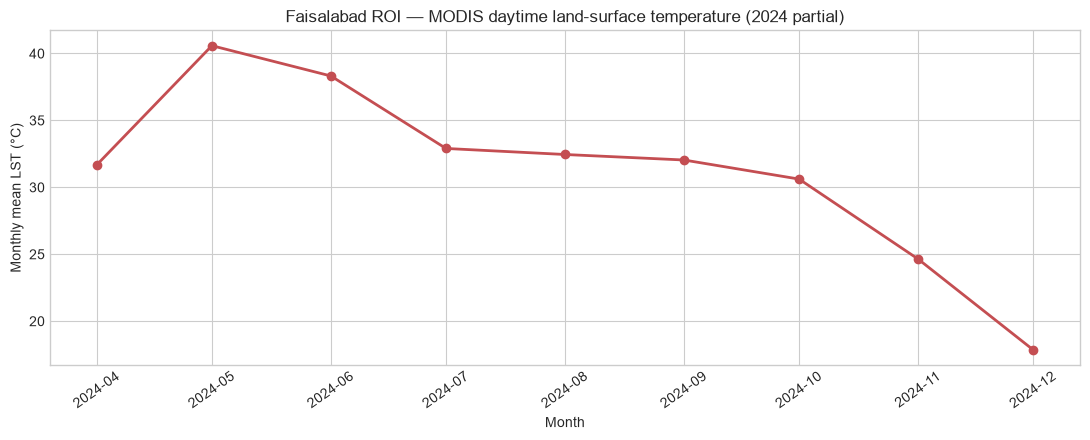

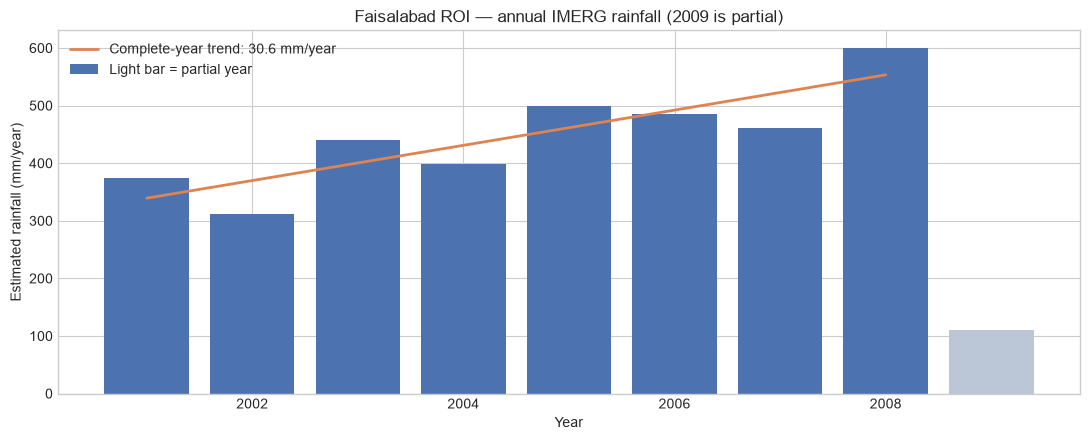

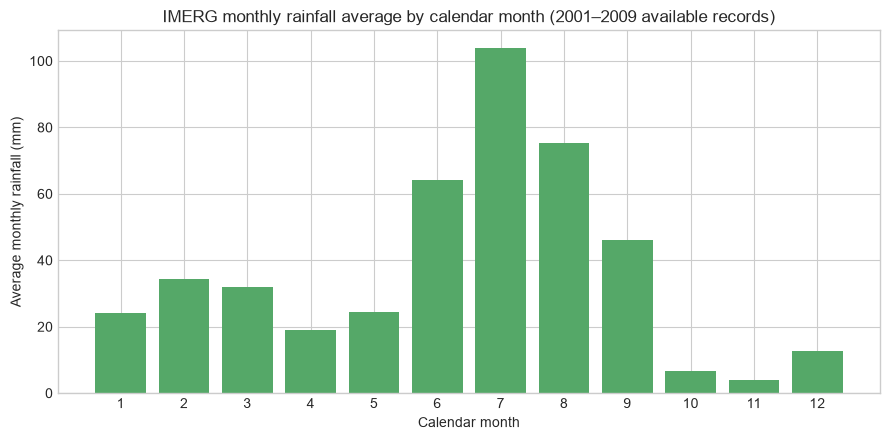

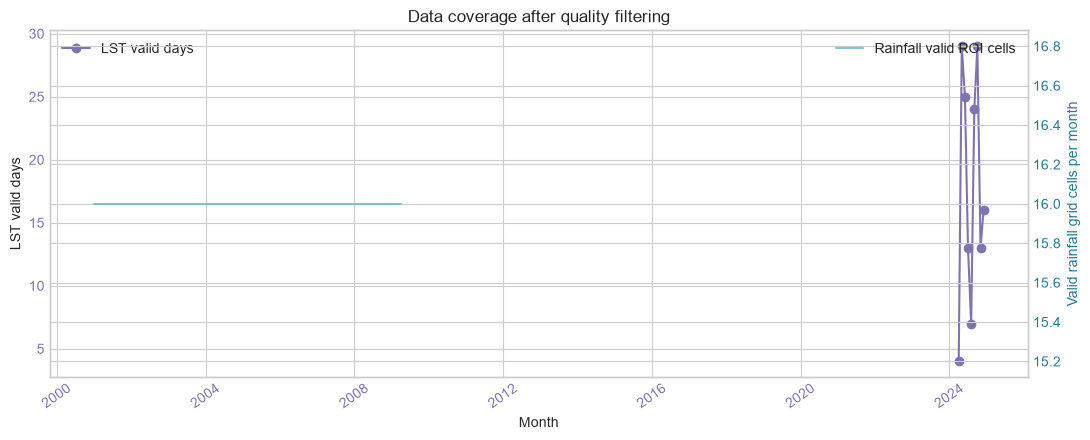

Saved figures:
- 01_lst_monthly.png
- 02_rainfall_annual_trend.png
- 03_rainfall_monthly_climatology.png
- 04_data_coverage.png


In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot([row['Month'] for row in lst_monthly], [row['LST_Celsius'] for row in lst_monthly], marker='o', color='#c44e52', linewidth=2)
ax.set(title='Faisalabad ROI — MODIS daytime land-surface temperature (2024 partial)',
       xlabel='Month', ylabel='Monthly mean LST (°C)')
ax.tick_params(axis='x', rotation=35)
fig.tight_layout()
fig.savefig(OUT_DIR / '01_lst_monthly.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar([row['Year'] for row in rain_annual], [row['Rain_mm_per_year'] for row in rain_annual],
       color=['#4c72b0' if row['Complete_Year'] else '#bbc7d7' for row in rain_annual],
       label='Light bar = partial year')
full = rain_complete_years
x = np.linspace(full[0]['Year'], full[-1]['Year'], 100)
ax.plot(x, rain_trend.intercept + rain_trend.slope * x, color='#dd8452', linewidth=2,
        label=f"Complete-year trend: {rain_trend.slope:.1f} mm/year")
ax.set(title='Faisalabad ROI — annual IMERG rainfall (2009 is partial)',
       xlabel='Year', ylabel='Estimated rainfall (mm/year)')
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / '02_rainfall_annual_trend.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 4.5))
climatology = {month: np.mean([row['Rain_mm_per_month'] for row in rain_monthly
                                  if row['Month_Number'] == month and np.isfinite(row['Rain_mm_per_month'])])
               if any(row['Month_Number'] == month and np.isfinite(row['Rain_mm_per_month']) for row in rain_monthly)
               else np.nan for month in range(1, 13)}
ax.bar(list(climatology), list(climatology.values()), color='#55a868')
ax.set(title='IMERG monthly rainfall average by calendar month (2001–2009 available records)',
       xlabel='Calendar month', ylabel='Average monthly rainfall (mm)', xticks=range(1, 13))
fig.tight_layout()
fig.savefig(OUT_DIR / '03_rainfall_monthly_climatology.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot([row['Month'] for row in lst_monthly], [row['Valid_Days'] for row in lst_monthly], marker='o', color='#8172b2', label='LST valid days')
ax.set(title='Data coverage after quality filtering', xlabel='Month', ylabel='LST valid days')
ax.tick_params(axis='y', labelcolor='#8172b2')
ax.tick_params(axis='x', rotation=35, labelcolor='#8172b2')
ax2 = ax.twinx()
ax2.plot([row['Date'] for row in rain_monthly], [row['Valid_Grid_Cells'] for row in rain_monthly], color='#64b5cd', alpha=0.8,
         label='Rainfall valid ROI cells')
ax2.set_ylabel('Valid rainfall grid cells per month', color='#287a91')
ax2.tick_params(axis='y', labelcolor='#287a91')
ax.legend(loc='upper left')
ax2.legend(loc='upper right')
fig.tight_layout()
fig.savefig(OUT_DIR / '04_data_coverage.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Saved figures:', *sorted(p.name for p in OUT_DIR.glob('*.png')), sep='\n- ')

## 7. Tables aur interpretation
Trend ki direction/slope aur p-value data se calculate hoti hai. Statistical association ka matlab causation nahi; chhoti year count aur alag temporal periods interpretation ko limit karte hain.

In [7]:
save_csv(OUT_DIR / 'lst_daily.csv', lst_daily)
save_csv(OUT_DIR / 'lst_monthly.csv', lst_monthly)
save_csv(OUT_DIR / 'lst_annual.csv', lst_annual)
save_csv(OUT_DIR / 'rainfall_monthly.csv', rain_monthly)
save_csv(OUT_DIR / 'rainfall_annual.csv', rain_annual)

direction = 'increasing' if rain_trend.slope > 0 else 'decreasing' if rain_trend.slope < 0 else 'flat'
significance = 'statistically significant at 5%' if rain_trend.pvalue < 0.05 else 'not statistically significant at 5%'
valid_lst_months = [row for row in lst_monthly if np.isfinite(row['LST_Celsius'])]
warmest = max(valid_lst_months, key=lambda row: row['LST_Celsius']) if valid_lst_months else None
wettest = max(rain_monthly, key=lambda row: row['Rain_mm_per_month'])
print('INTERPRETATION')
print(f"• Complete-year rainfall trend ({rain_trend_summary['Complete years used']}): {direction}, {rain_trend.slope:.2f} mm/year; p={rain_trend.pvalue:.4f} ({significance}).")
partial_years = [row for row in rain_annual if not row['Complete_Year']]
print(f"• Regression uses only {len(rain_complete_years)} complete years; partial year(s) {[(row['Year'], row['Months_With_Data']) for row in partial_years]} are excluded from the trend.")
if warmest is not None:
    lst_values = [row['LST_Celsius'] for row in valid_lst_months]
    print(f"• Available 2024 LST monthly means range from {min(lst_values):.1f} to {max(lst_values):.1f} °C; warmest observed month: {warmest['Month']:%Y-%m}.")
print(f"• Largest individual monthly rainfall estimate in this record: {wettest['Date']:%Y-%m} ({wettest['Rain_mm_per_month']:.1f} mm). This is not a long-term monthly climatology maximum claim.")
print('• LST covers only part of 2024; a multi-year LST trend is not estimable from these files.')
print('• LST (2024) and rainfall (2001–2009) periods do not overlap; no contemporaneous correlation or causal interpretation is valid.')
print('• LST is land-surface temperature, not near-surface air temperature. ROI means represent the configured box, not a station measurement.')
print('\nOutput files saved under:', OUT_DIR.resolve())

INTERPRETATION
• Complete-year rainfall trend (2001–2008): increasing, 30.59 mm/year; p=0.0070 (statistically significant at 5%).
• Regression uses only 8 complete years; partial year(s) [(2009, 4)] are excluded from the trend.
• Available 2024 LST monthly means range from 17.9 to 40.6 °C; warmest observed month: 2024-05.
• Largest individual monthly rainfall estimate in this record: 2007-07 (172.4 mm). This is not a long-term monthly climatology maximum claim.
• LST covers only part of 2024; a multi-year LST trend is not estimable from these files.
• LST (2024) and rainfall (2001–2009) periods do not overlap; no contemporaneous correlation or causal interpretation is valid.
• LST is land-surface temperature, not near-surface air temperature. ROI means represent the configured box, not a station measurement.

Output files saved under: C:\Users\Mr.Laptop Point\Desktop\Us Final_Faisalabad_Task\outputs
